# P2: ¿de qué tamaño debe ser cada ventana de tiempo?

**Objetivo:** elegir con datos el tamaño de la ventana en la que se predice el riesgo de P2 (30 minutos, 1, 2, 3 o 4 horas, o el día completo). Las instrucciones dejan la granularidad al equipo; el ML Canvas proponía 2 h sin justificarlo.

Al final se toman otras decisiones de P2: **a qué hora se reinicia el inventario** estimado de cada estación (sección 11), **cómo se construye la etiqueta** con el inventario simulado (sección 12) y **cómo se parten los datos en el tiempo** (sección 13).

**Idea:** sin inventario de bicicletas, aproximamos el riesgo con el **balance neto** de cada estación en cada ventana: `llegadas − salidas`. Si en una ventana salen muchas más bicis de las que llegan, comparado con la capacidad de la estación, se puede vaciar; si llegan muchas más, se puede llenar.

**Umbral provisional:** para comparar ventanas usamos `|neto| ≥ 50% de la capacidad` como "riesgo". **No es el umbral final** (ese se aplica en la sección 12); solo sirve para comparar los tamaños de ventana con la misma regla.

**Datos:** `data/interim/viajes.parquet` desde `FECHA_INICIO` (2022-03-01) y el catálogo de estaciones.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from mibici_mlops.config import (
    FECHA_INICIO,
    FECHA_INICIO_PRUEBA,
    FECHA_INICIO_VALIDACION,
    INTERIM_DATA_DIR,
    RAW_DATA_DIR,
)

UMBRAL_PROVISIONAL = 0.5  # fracción de la capacidad; solo para comparar ventanas

2026-10-17 19:24:24.380 | INFO     | mibici_mlops.config:<module>:11 - PROJ_ROOT path is: C:\Users\rogas\PycharmProjects\MiBici_MLOps


## 1. Estaciones y su capacidad

El catálogo trae la capacidad (`dpcapacity`, número de anclajes). Hay estaciones con capacidad 0: las quitamos porque no se puede dividir entre 0.

`set_index("id")` pone el id de la estación como índice para poder buscar la capacidad con `.map()` (el "BUSCARV" que vimos en `dataset.py`).

In [2]:
estaciones = pd.read_csv(RAW_DATA_DIR / "estaciones" / "nomenclatura_2026_09.csv")
print(f"Estaciones con capacidad 0: {(estaciones['dpcapacity'] == 0).sum()}")

estaciones = estaciones[estaciones["dpcapacity"] > 0].set_index("id")
estaciones["dpcapacity"].describe()

Estaciones con capacidad 0: 4


count    480.000000
mean      17.022917
std        3.843697
min       11.000000
25%       15.000000
50%       15.000000
75%       19.000000
max       39.000000
Name: dpcapacity, dtype: float64

## 2. Viajes desde la fecha de corte

Como en el notebook del periodo, leemos solo las columnas necesarias. `filters` lee solo los viajes desde `FECHA_INICIO` (definida en `config.py`).

In [3]:
viajes = pd.read_parquet(
    INTERIM_DATA_DIR / "viajes.parquet",
    columns=["inicio", "fin", "origen_id", "destino_id"],
    filters=[("inicio", ">=", pd.Timestamp(FECHA_INICIO))],
)
print(f"Viajes: {len(viajes):,}")

Viajes: 20,431,557


## 3. Salidas y llegadas por estación y media hora

- `.dt.floor("30min")` redondea cada fecha **hacia abajo** a la media hora: `08:47:12` → `08:30`. Así todos los viajes entre 8:30 y 8:59 caen en la misma media hora. Es la unidad más chica que comparamos; las ventanas más grandes se arman sumando medias horas.
- `groupby([columna1, columna2])` agrupa por **dos** cosas a la vez: estación **y** hora. `.size()` cuenta cuántos viajes hay en cada grupo.
- Una **salida** se cuenta en la estación de origen a la hora de inicio; una **llegada**, en la estación de destino a la hora de fin.

In [4]:
salidas = viajes.groupby(["origen_id", viajes["inicio"].dt.floor("30min")]).size()
llegadas = viajes.groupby(["destino_id", viajes["fin"].dt.floor("30min")]).size()

salidas.index.names = ["estacion", "hora"]
llegadas.index.names = ["estacion", "hora"]
salidas.head()

estacion  hora               
2         2022-03-01 06:30:00    1
          2022-03-01 07:00:00    2
          2022-03-01 07:30:00    1
          2022-03-01 08:00:00    2
          2022-03-01 08:30:00    2
dtype: int64

Ahora juntamos salidas y llegadas en una sola tabla.

- `pd.concat({...}, axis=1)` pone las dos series **lado a lado** como columnas (con los nombres `salidas` y `llegadas`), alineadas por estación y hora.
- Si en una hora hubo salidas pero ninguna llegada, la llegada queda vacía (`NaN`). `.fillna(0)` la cambia a 0, porque significa "no llegó nadie".
- Quitamos las estaciones que no están en el catálogo (o tienen capacidad 0) y agregamos la capacidad con `.map()`.

In [5]:
por_media_hora = pd.concat({"salidas": salidas, "llegadas": llegadas}, axis=1).fillna(0).reset_index()
por_media_hora = por_media_hora[por_media_hora["estacion"].isin(estaciones.index)]

por_media_hora["neto"] = por_media_hora["llegadas"] - por_media_hora["salidas"]
por_media_hora["capacidad"] = por_media_hora["estacion"].map(estaciones["dpcapacity"])
por_media_hora.head()

,estacion,hora,salidas,llegadas,neto,capacidad
0,2,2022-03-01 06:30:00,1.0,0.0,-1.0,15
1,2,2022-03-01 07:00:00,2.0,0.0,-2.0,15
2,2,2022-03-01 07:30:00,1.0,3.0,2.0,15
3,2,2022-03-01 08:00:00,2.0,2.0,0.0,15
4,2,2022-03-01 08:30:00,2.0,8.0,6.0,15


## 4. Medida 1: ¿cuánto duran las horas pico?

Si los desbalances fuertes duran unas 2–3 horas, una ventana mucho más larga los diluye y una mucho más corta los parte.

Calculamos, para días hábiles, el promedio del balance neto **en valor absoluto** (`.abs()`, sin signo) por hora del día: cuánto se desbalancea una estación típica en cada hora, sin importar si se vacía o se llena.

Como los conteos están por media hora, primero sumamos las dos medias horas de cada hora. Nota: solo cuenta las horas en que la estación tuvo al menos un viaje.

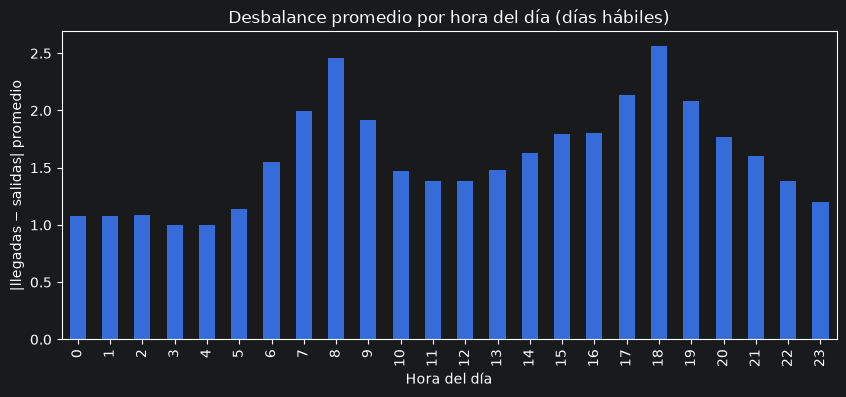

In [6]:
habiles = por_media_hora[por_media_hora["hora"].dt.dayofweek < 5]  # 0 = lunes ... 4 = viernes
neto_por_hora = habiles.groupby(["estacion", habiles["hora"].dt.floor("h")])["neto"].sum().reset_index()
desbalance_por_hora = neto_por_hora["neto"].abs().groupby(neto_por_hora["hora"].dt.hour).mean()

fig, ax = plt.subplots(figsize=(10, 4))
desbalance_por_hora.plot(kind="bar", ax=ax)
ax.set_title("Desbalance promedio por hora del día (días hábiles)")
ax.set_xlabel("Hora del día")
ax.set_ylabel("|llegadas − salidas| promedio")
plt.show()

## 5. Medida 2: ¿qué tan rara es la clase de riesgo con cada ventana?

Con ventanas muy cortas casi nunca se ve riesgo y el modelo tendría muy pocos ejemplos para aprender.

Para cada tamaño:

1. Agrupamos en ventanas con `dt.floor`: `dt.floor("120min")` redondea a bloques de 2 horas (00:00, 02:00, 04:00…) y `dt.floor("1440min")` agrupa el día completo. Usamos minutos para poder incluir ventanas de 30 minutos.
2. Sumamos el balance neto de cada estación en cada ventana.
3. Contamos las ventanas en que `neto / capacidad` pasa el umbral provisional.

El porcentaje se calcula sobre **todas** las ventanas posibles (también las que no tuvieron viajes): por cada estación, desde su primer hasta su último día con viajes.

In [7]:
dias_activa = por_media_hora.groupby("estacion")["hora"].agg(["min", "max"])
total_dias = ((dias_activa["max"].dt.normalize() - dias_activa["min"].dt.normalize()).dt.days + 1).sum()

minutos_por_ventana = [30, 60, 120, 180, 240, 1440]  # 1440 = día completo
filas = []
for minutos in minutos_por_ventana:
    por_ventana = por_media_hora.groupby(["estacion", por_media_hora["hora"].dt.floor(f"{minutos}min")]).agg(
        neto=("neto", "sum"), capacidad=("capacidad", "first")
    )
    proporcion = por_ventana["neto"] / por_ventana["capacidad"]
    total_ventanas = total_dias * 1440 / minutos
    se_vacia = (proporcion <= -UMBRAL_PROVISIONAL).sum()
    se_llena = (proporcion >= UMBRAL_PROVISIONAL).sum()
    filas.append(
        {
            "horas": minutos / 60,
            "ventanas_se_vacia": se_vacia,
            "ventanas_se_llena": se_llena,
            "pct_se_vacia": se_vacia / total_ventanas * 100,
            "pct_se_llena": se_llena / total_ventanas * 100,
        }
    )

pd.DataFrame(filas).set_index("horas").round(2)

,ventanas_se_vacia,ventanas_se_llena,pct_se_vacia,pct_se_llena
horas,,,,
0.5,11462,12779,0.04,0.05
1.0,28932,30543,0.21,0.22
2.0,60364,61984,0.86,0.89
3.0,84452,77690,1.82,1.67
4.0,91983,88068,2.64,2.52
24.0,63803,58606,10.97,10.08


## 6. Medida 3: ¿una estación tiene los dos riesgos el mismo día?

Si pasa seguido, una ventana de un día completo pierde información: no puede decir "se vacía en la mañana **y** se llena en la tarde".

Para cada ventana menor a un día marcamos si la estación se vació o se llenó, y luego revisamos por estación y día si tuvo alguno (`.any()`) de cada tipo.

In [8]:
filas = []
for minutos in [30, 60, 120, 180, 240]:  # sin el día completo
    por_ventana = (
        por_media_hora.groupby(["estacion", por_media_hora["hora"].dt.floor(f"{minutos}min")])
        .agg(neto=("neto", "sum"), capacidad=("capacidad", "first"))
        .reset_index()
    )
    proporcion = por_ventana["neto"] / por_ventana["capacidad"]
    por_ventana["se_vacia"] = proporcion <= -UMBRAL_PROVISIONAL
    por_ventana["se_llena"] = proporcion >= UMBRAL_PROVISIONAL

    por_dia = por_ventana.groupby(["estacion", por_ventana["hora"].dt.normalize()])[
        ["se_vacia", "se_llena"]
    ].any()
    dias_con_riesgo = (por_dia["se_vacia"] | por_dia["se_llena"]).sum()
    dias_con_ambos = (por_dia["se_vacia"] & por_dia["se_llena"]).sum()
    filas.append(
        {
            "horas": minutos / 60,
            "dias_con_riesgo": dias_con_riesgo,
            "dias_con_ambos": dias_con_ambos,
            "pct_con_ambos": dias_con_ambos / dias_con_riesgo * 100,
        }
    )

pd.DataFrame(filas).set_index("horas").round(1)

,dias_con_riesgo,dias_con_ambos,pct_con_ambos
horas,,,
0.5,16471,1602,9.7
1.0,42147,4758,11.3
2.0,88546,14146,16.0
3.0,118271,22453,19.0
4.0,133179,25351,19.0


## 7. ¿Dónde empiezan los bloques? Pares contra impares

La gráfica de la medida 1 muestra picos de **7 a 9 h** y de **17 a 19 h**. Pero `dt.floor("2h")` arma bloques que empiezan en horas **pares** (6–8, 8–10, …, 16–18, 18–20), así que cada pico queda **partido en dos bloques** y su desbalance se reparte entre ambos.

Si los bloques empiezan en horas **impares** (7–9, 9–11, …, 17–19), cada pico queda en un solo bloque. Comparamos las dos versiones con las medidas 2 y 3.

**Cómo se desplazan los bloques:** `dt.floor` siempre empieza en horas pares, así que:

1. Restamos 1 hora: las `07:30` pasan a `06:30`.
2. Redondeamos a bloques de 2 h: `06:30` → `06:00`.
3. Sumamos la hora de vuelta: `06:00` → `07:00`.

Resultado: todo lo que pasa entre 7:00 y 8:59 cae en el bloque que empieza a las `07:00`.

La función `medir_bloques_2h` hace las medidas 2 y 3 para un desfase dado (0 = pares, 1 = impares), para no repetir el código dos veces.

In [9]:
def medir_bloques_2h(desfase_horas):
    desfase = pd.Timedelta(hours=desfase_horas)
    inicio_bloque = (por_media_hora["hora"] - desfase).dt.floor("2h") + desfase

    por_ventana = (
        por_media_hora.groupby(["estacion", inicio_bloque])
        .agg(neto=("neto", "sum"), capacidad=("capacidad", "first"))
        .reset_index()
    )
    proporcion = por_ventana["neto"] / por_ventana["capacidad"]
    por_ventana["se_vacia"] = proporcion <= -UMBRAL_PROVISIONAL
    por_ventana["se_llena"] = proporcion >= UMBRAL_PROVISIONAL

    por_dia = por_ventana.groupby(["estacion", por_ventana["hora"].dt.normalize()])[
        ["se_vacia", "se_llena"]
    ].any()
    dias_con_riesgo = (por_dia["se_vacia"] | por_dia["se_llena"]).sum()
    total_ventanas = total_dias * 24 / 2

    return {
        "ventanas_se_vacia": por_ventana["se_vacia"].sum(),
        "ventanas_se_llena": por_ventana["se_llena"].sum(),
        "pct_se_vacia": por_ventana["se_vacia"].sum() / total_ventanas * 100,
        "pct_se_llena": por_ventana["se_llena"].sum() / total_ventanas * 100,
        "pct_dias_con_ambos": (por_dia["se_vacia"] & por_dia["se_llena"]).sum()
        / dias_con_riesgo
        * 100,
    }


pd.DataFrame(
    {
        "pares (6–8, 8–10, …)": medir_bloques_2h(0),
        "impares (7–9, 9–11, …)": medir_bloques_2h(1),
    }
).round(2)

,"pares (6–8, 8–10, …)","impares (7–9, 9–11, …)"
ventanas_se_vacia,60364.00,62379.00
ventanas_se_llena,61984.00,59344.00
pct_se_vacia,0.86,0.89
pct_se_llena,0.89,0.85
pct_dias_con_ambos,15.98,16.08


## 8. Medida 4: ¿cuánto dura un viaje?

Si los viajes duran mucho comparado con la ventana, muchas bicis salen en una ventana y llegan en la siguiente: la ventana ve la salida pero no la llegada. Medimos:

- La duración de los viajes en minutos (`fin − inicio`; `.dt.total_seconds() / 60` convierte la diferencia de fechas a minutos).
- Qué porcentaje de viajes **termina en una ventana distinta** a la que empezó, para cada tamaño.

In [10]:
duracion_min = (viajes["fin"] - viajes["inicio"]).dt.total_seconds() / 60
print("Duración de los viajes (minutos), por percentil:")
print(duracion_min.quantile([0.25, 0.5, 0.75, 0.95, 0.99]).round(1))

cruzan = {
    minutos / 60: (
        viajes["inicio"].dt.floor(f"{minutos}min") != viajes["fin"].dt.floor(f"{minutos}min")
    ).mean()
    * 100
    for minutos in [30, 60, 120, 180, 240]
}
pd.Series(cruzan, name="pct_termina_en_otra_ventana").round(1)

Duración de los viajes (minutos), por percentil:
0.25     5.7
0.50     9.4
0.75    14.8
0.95    24.2
0.99    32.8
dtype: float64


0.5    35.0
1.0    17.5
2.0     8.6
3.0     6.1
4.0     4.4
Name: pct_termina_en_otra_ventana, dtype: float64

## 9. Medida 5: ¿cuánto dura un evento de desbalance?

Las medidas anteriores descartan 30 minutos, 1 hora y el día completo, pero no distinguen entre 2, 3 y 4 horas. Para eso medimos **cuánto dura un evento** de vaciado o llenado.

**Ejemplo:** una estación se vacía en la mañana. Bicis que se van (salidas − llegadas) cada media hora:

```
6:00  6:30  7:00  7:30  8:00  8:30  9:00  9:30
  0     1     4     5     5     4     1     0      → en total se van 20
```

- En la **mejor hora** (7:30–8:30) se van 10 de 20: **50%**.
- En las **mejores 2 horas** (7:00–9:00) se van 18 de 20: **90%**.
- En las **mejores 3 horas** se van las 20: **100%**.

Hacemos esa cuenta para todas las ventanas con riesgo. Si las mejores 2 horas de una ventana de 3 o 4 horas ya concentran casi todo el desbalance, las horas extra solo diluyen el "cuándo".

**Cómo lo calcula la función `concentracion`:**

1. `bloque`: el inicio de la ventana grande; `posicion`: qué media hora es dentro del bloque (0, 1, 2, …).
2. `.transform("sum")` calcula el total del bloque y lo pone **en cada fila** (a diferencia de `.sum()`, que deja una fila por grupo). Así podemos quedarnos solo con los bloques con riesgo.
3. `pivot_table` deja una fila por bloque y una columna por media hora, como en el ejemplo.
4. Sumamos cada grupo de medias horas consecutivas (`.iloc[:, i : i + n]`) para obtener todos los sub-bloques posibles y nos quedamos con el más cargado **en la dirección del riesgo** (`np.sign` da −1 si la estación se vacía y +1 si se llena).
5. Dividimos entre el total del bloque. `.clip(0, 1)` limita el resultado entre 0% y 100%.

In [11]:
def concentracion(minutos_ventana, minutos_sub):
    datos = por_media_hora[["estacion", "hora", "neto", "capacidad"]].copy()
    datos["bloque"] = datos["hora"].dt.floor(f"{minutos_ventana}min")
    datos["posicion"] = (datos["hora"] - datos["bloque"]) // pd.Timedelta("30min")

    # Solo los bloques con riesgo
    datos["neto_bloque"] = datos.groupby(["estacion", "bloque"])["neto"].transform("sum")
    datos = datos[datos["neto_bloque"].abs() / datos["capacidad"] >= UMBRAL_PROVISIONAL]

    # Una fila por bloque, una columna por media hora
    ancho = datos.pivot_table(
        index=["estacion", "bloque"], columns="posicion", values="neto", aggfunc="sum", fill_value=0
    ).reindex(columns=range(minutos_ventana // 30), fill_value=0)

    total = ancho.sum(axis=1)
    signo = np.sign(total)
    n = minutos_sub // 30
    sub_bloques = pd.concat(
        [ancho.iloc[:, i : i + n].sum(axis=1) for i in range(ancho.shape[1] - n + 1)], axis=1
    )
    mejor = sub_bloques.mul(signo, axis=0).max(axis=1)
    proporcion = (mejor / (total * signo)).clip(0, 1)

    return {
        "ventanas_con_riesgo": len(proporcion),
        "mediana_pct_en_mejor_sub_bloque": proporcion.median() * 100,
        "pct_ventanas_con_80_o_mas": (proporcion >= 0.8).mean() * 100,
    }


pd.DataFrame(
    {
        "ventana 2 h, mejor 1 h": concentracion(120, 60),
        "ventana 3 h, mejor 2 h": concentracion(180, 120),
        "ventana 4 h, mejor 2 h": concentracion(240, 120),
        "ventana 4 h, mejor 3 h": concentracion(240, 180),
    }
).T.round(1)

,ventanas_con_riesgo,mediana_pct_en_mejor_sub_bloque,pct_ventanas_con_80_o_mas
"ventana 2 h, mejor 1 h",122348.0,75.0,39.8
"ventana 3 h, mejor 2 h",162142.0,88.2,71.8
"ventana 4 h, mejor 2 h",180051.0,84.6,60.7
"ventana 4 h, mejor 3 h",180051.0,100.0,88.5


## 10. Conclusión: ventanas de 2 horas

Comparamos ventanas de 30 minutos, 1, 2, 3 y 4 horas y el día completo (en las tablas, `horas = 0.5` es 30 minutos y `24` el día completo):

| Medida | Resultado | Qué implica |
|---|---|---|
| 1. Horas pico | Picos de 7 a 9 h y de 17 a 19 h en días hábiles; duran ~2–3 h | Ventanas de 2 o 3 h siguen la forma de los picos |
| 2. Rareza del riesgo | 30 min: 0.04% de ventanas con riesgo; 1 h: 0.2%; 2 h: ~0.9% (~60 mil por clase); 3 h: ~1.8%; día: ~11% | **Descarta 30 min y 1 h**: muy pocos ejemplos de riesgo |
| 3. Ambos riesgos el mismo día | Con ventanas de 2 a 4 h, 16–19% de los días con riesgo tienen los dos tipos | **Descarta el día completo**: no puede representar "se vacía en la mañana y se llena en la tarde" ni decir a qué hora ir |
| Bloques pares vs. impares | Sin diferencia (0.86% vs. 0.89%) | No importa dónde empiecen los bloques; se usan los pares (`dt.floor`) |
| 4. Duración de los viajes | Mediana de ~9 min; 99% dura menos de 33 min. Terminan en otra ventana: 35% con 30 min, 17.5% con 1 h, 8.6% con 2 h | Con 2 h o más, la gran mayoría de los viajes empieza y termina en la misma ventana |
| 5. Duración de los eventos | En ventanas con riesgo, el mejor sub-bloque concentra (mediana) el 75% del desbalance si es de 1 h, 85–88% si es de 2 h y 100% si es de 3 h | Un evento dura entre 2 y 3 horas: **1 h lo corta**; 2 h captura su núcleo; 3 h lo captura completo |

Un evento de desbalance dura entre 2 y 3 horas. **Elegimos 2 horas porque el objetivo de P2 es saber cuándo una estación estará en riesgo**: 2 horas captura el núcleo del evento (85–88% del desbalance) con más precisión sobre el momento que 3 horas, que lo captura completo pero diluye cuándo ocurre. Además deja ~60 mil ejemplos por clase de riesgo y coincide con el ML Canvas.

**Limitación:** estos porcentajes usan un umbral provisional (50% de la capacidad) y el balance de cada ventana por separado. La etiqueta final de P2 puede usar otro umbral y el inventario acumulado, así que los porcentajes cambiarán; la comparación entre tamaños de ventana sigue siendo válida porque todos se midieron con la misma regla.

**Otros hallazgos para después:** 3.6% de los viajes dura menos de 1 minuto y 45 viajes duran más de 24 horas. Hay que revisar si son viajes válidos.

## 11. Otra decisión de P2: ¿a qué hora se reinicia el inventario?

Para la etiqueta, el inventario estimado de cada estación se reinicia una vez al día al 50% de su capacidad (ver `references/decisiones_p2.md`, decisión 4). El reinicio debe hacerse a la hora con **menos actividad**, para suponer que ahí ocurre el rebalanceo sin cortar viajes a la mitad.

La gráfica de la medida 1 mide el desbalance, no la actividad. Aquí contamos directamente **cuántos viajes empiezan en cada hora del día**, en promedio por día.

In [12]:
dias = viajes["inicio"].dt.normalize().nunique()
viajes_por_hora = viajes["inicio"].dt.hour.value_counts().sort_index()

pd.DataFrame(
    {
        "viajes_por_dia": (viajes_por_hora / dias).round(0),
        "pct_del_total": (viajes_por_hora / viajes_por_hora.sum() * 100).round(2),
    }
)

,viajes_por_dia,pct_del_total
inicio,,
0,80.0,0.66
1,2.0,0.02
2,0.0,0.00
3,0.0,0.00
4,0.0,0.00
5,84.0,0.68
6,321.0,2.63
7,646.0,5.30
8,935.0,7.66


Para cada hora candidata contamos cuántos viajes están **a medio camino** en ese momento (empezaron antes y terminan después). Esos viajes quedarían cortados por el reinicio.

`corte` es la hora candidata en el día en que empezó el viaje. Un viaje que empieza a las 23:50 y termina a las 00:10 del día siguiente cruza la medianoche de **ese día siguiente**, por eso también revisamos `corte + 1 día`.

In [13]:
un_dia = pd.Timedelta(days=1)
en_curso = {}
for hora in [0, 2, 3, 4, 5]:
    corte = viajes["inicio"].dt.normalize() + pd.Timedelta(hours=hora)
    cruza_hoy = (viajes["inicio"] < corte) & (viajes["fin"] > corte)
    cruza_manana = (viajes["inicio"] < corte + un_dia) & (viajes["fin"] > corte + un_dia)
    en_curso[f"{hora:02d}:00"] = (cruza_hoy | cruza_manana).sum() / dias

pd.Series(en_curso, name="viajes_en_curso_por_dia").round(1)

00:00    22.6
02:00     0.9
03:00     0.4
04:00     0.4
05:00     0.4
Name: viajes_en_curso_por_dia, dtype: float64

### Conclusión: reinicio a las 4:00

- Entre la **1:00 y las 5:00 casi no hay viajes** (0 por día de 2:00 a 4:59): el sistema prácticamente no opera en ese horario.
- A las **00:00** hay ~23 viajes por día a medio camino; a las 3:00 y 4:00, prácticamente ninguno.
- Se elige **4:00**: es la última hora sin actividad antes de que el servicio arranque, no corta viajes y coincide con el inicio de un bloque de 2 horas (04:00–06:00). Cualquier hora entre 2:00 y 4:00 daría el mismo resultado.

Esto también explica el desbalance de ~1.0 de madrugada en la gráfica de la medida 1: casi no hay viajes a esas horas, y una hora con un solo viaje ya tiene un desbalance de 1.

## 12. La etiqueta: inventario simulado

Las secciones 5 a 9 usaron un umbral provisional y el balance de cada ventana por separado, suficiente para comparar tamaños de ventana. Ahora construimos la **etiqueta final** de P2, con las reglas de `references/decisiones_p2.md`:

- **Decisión 4:** cada estación empieza su día a las **4:00** con el **50% de su capacidad**. Durante el día el inventario se acumula (más llegadas, menos salidas); no se reinicia en cada ventana.
- **Decisión 5:** una ventana de 2 horas es **"se vacía"** si el inventario más bajo llega a **0 o menos**, y **"se llena"** si el más alto llega a la **capacidad o más**.

Pasos:

1. **Movimientos:** cada viaje es una salida en su estación de origen y una llegada en su estación de destino.
2. **Inventario:** se acumulan los movimientos de cada estación durante el día.
3. **Mínimo y máximo** del inventario en cada ventana de 2 horas.
4. **Ventanas sin viajes:** heredan el inventario de la ventana anterior.
5. **Comparar umbrales**, para comprobar las cifras de la decisión 5.

**Memoria:** esta sección usa ~5 GB de RAM. Si la computadora se pone lenta, reinicia el kernel y corre solo la primera celda (imports) y las secciones 1, 2 y 12.

In [14]:
HORA_REINICIO = 4  # decisión 4: el día de la simulación va de las 4:00 a las 3:59
INVENTARIO_INICIAL = 0.5  # decisión 4: fracción de la capacidad al empezar el día

### 12.1 Movimientos

Cada viaje mueve una bicicleta:

- una **salida** (−1) en la estación de origen, a la hora de inicio;
- una **llegada** (+1) en la estación de destino, a la hora de fin.

Armamos una tabla de salidas y otra de llegadas con las mismas columnas (`estacion`, `momento`, `cambio`) y las juntamos **una debajo de la otra** con `pd.concat([...])`. En la sección 3 usamos `axis=1` para ponerlas lado a lado; sin `axis=1` se apilan. `ignore_index=True` vuelve a numerar las filas desde 0.

Después nos quedamos solo con las estaciones que tienen capacidad. Se filtra **al final** a propósito: 2 estaciones con viajes no están en la nomenclatura (~4 mil viajes). Esas estaciones no se pueden etiquetar porque no sabemos su capacidad, pero una bici que sale de ellas sí **llega** a una estación válida, y esa llegada debe contar.

In [15]:
movimientos = pd.concat(
    [
        pd.DataFrame({"estacion": viajes["origen_id"], "momento": viajes["inicio"], "cambio": -1}),
        pd.DataFrame({"estacion": viajes["destino_id"], "momento": viajes["fin"], "cambio": 1}),
    ],
    ignore_index=True,
)
movimientos = movimientos[movimientos["estacion"].isin(estaciones.index)]
print(f"Movimientos: {len(movimientos):,} (2 por viaje serían {2 * len(viajes):,})")

Movimientos: 40,859,031 (2 por viaje serían 40,863,114)


### 12.2 Inventario durante el día

**El día empieza a las 4:00.** A cada momento le restamos 4 horas antes de quedarnos con la fecha (`.dt.normalize()` deja solo la fecha, a las 00:00). Así, lo que pasa entre las 0:00 y las 3:59 cuenta en el día **anterior**:

| momento | − 4 horas | día |
|---|---|---|
| martes 08:15 | martes 04:15 | martes |
| martes 02:00 | lunes 22:00 | lunes |

**Suma acumulada (`cumsum`).** Cada fila suma su cambio más todos los anteriores. Estación con capacidad 20, que empieza con 10:

| cambio | cumsum | inventario (10 + cumsum) |
|---|---|---|
| −1 | −1 | 9 |
| −1 | −2 | 8 |
| +1 | −1 | 9 |
| −1 | −2 | 8 |

Para que funcione:

1. `cumsum` suma en el orden de las filas, así que primero ordenamos los movimientos por hora con `sort_values("momento")`. Con `kind="stable"`, si dos movimientos caen en el mismo segundo conservan el orden en que se juntaron (primero las salidas). Sin eso, pandas puede acomodarlos en otro orden según su versión o el orden de los datos, y la etiqueta cambiaría un poco: es parte de que el resultado sea reproducible.
2. `groupby(["estacion", "dia"])["cambio"].cumsum()` hace la suma **por separado** para cada estación y cada día: al empezar un día nuevo, la suma vuelve a empezar desde 0.

**Capacidad impar:** casi todas las estaciones tienen capacidad impar (15, 19, 23…). El 50% de 15 es 7.5 y **no lo redondeamos**: con 7 salidas netas el inventario queda en 0.5 y con 8 en −0.5 (se vacía); con 8 llegadas netas queda en 15.5 (se llena). Las dos clases quedan a la misma distancia, como pide la decisión 4. Si redondeáramos a 7, bastarían 7 salidas para vaciarse, pero harían falta 8 llegadas para llenarse.

In [16]:
movimientos = movimientos.sort_values("momento", kind="stable", ignore_index=True)
movimientos["dia"] = (movimientos["momento"] - pd.Timedelta(hours=HORA_REINICIO)).dt.normalize()
movimientos["inventario"] = (
    INVENTARIO_INICIAL * movimientos["estacion"].map(estaciones["dpcapacity"])
    + movimientos.groupby(["estacion", "dia"])["cambio"].cumsum()
)
movimientos.head()

,estacion,momento,cambio,dia,inventario
0,80,2022-03-01 00:00:29,-1,2022-02-28,6.5
1,39,2022-03-01 00:01:00,-1,2022-02-28,6.5
2,323,2022-03-01 00:02:16,-1,2022-02-28,8.5
3,231,2022-03-01 00:05:02,-1,2022-02-28,6.5
4,21,2022-03-01 00:07:21,1,2022-02-28,12.5


En la tabla, los movimientos del 1 de marzo antes de las 4:00 quedan en el día **28 de febrero**. Ese día está incompleto (los datos empiezan el 1 de marzo), así que no lo usaremos para la etiqueta.

**Ejemplo:** el inventario simulado de la estación GDL-036 un martes. `ax.step(..., where="post")` dibuja escalones: el inventario se queda igual hasta el siguiente movimiento. Las líneas punteadas son los umbrales de la decisión 5.

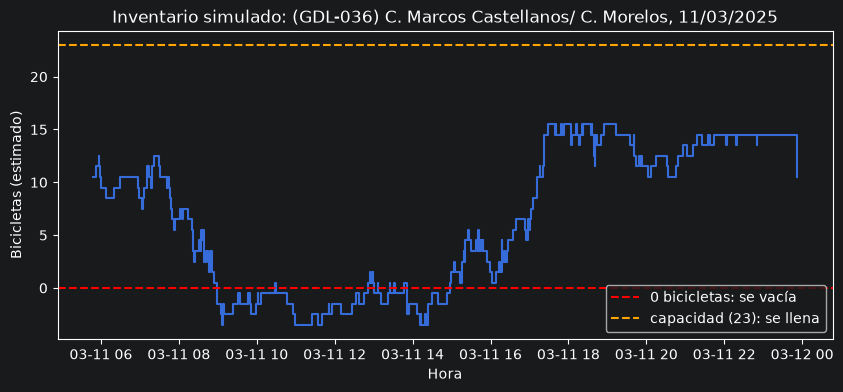

In [17]:
ESTACION_EJEMPLO = 38  # (GDL-036) C. Marcos Castellanos / C. Morelos
DIA_EJEMPLO = pd.Timestamp("2025-03-11")  # martes

ejemplo = movimientos[
    (movimientos["estacion"] == ESTACION_EJEMPLO) & (movimientos["dia"] == DIA_EJEMPLO)
]
capacidad_ejemplo = estaciones.loc[ESTACION_EJEMPLO, "dpcapacity"]

fig, ax = plt.subplots(figsize=(10, 4))
ax.step(ejemplo["momento"], ejemplo["inventario"], where="post")
ax.axhline(0, color="red", linestyle="--", label="0 bicicletas: se vacía")
ax.axhline(
    capacidad_ejemplo, color="orange", linestyle="--", label=f"capacidad ({capacidad_ejemplo}): se llena"
)
ax.set_title(f"Inventario simulado: {estaciones.loc[ESTACION_EJEMPLO, 'name']}, {DIA_EJEMPLO:%d/%m/%Y}")
ax.set_xlabel("Hora")
ax.set_ylabel("Bicicletas (estimado)")
ax.legend(loc="lower right")
plt.show()

**Cómo leer la gráfica:** la estación empieza el día con 11.5 bicis (50% de 23). En la mañana salen muchas más de las que llegan: a las 8:58 el inventario simulado llega a 0 o menos por primera vez y se queda alrededor de 0 hasta las 14:52, la última vez que está en 0 o menos. En la tarde se recupera, pero nunca llega a la capacidad. Con ventanas de 2 horas:

| Ventana | Inventario más bajo | Clase |
|---|---|---|
| 6–8 | 5.5 | sin riesgo |
| 8–10 | −3.5 | se vacía |
| 10–12 | −3.5 | se vacía |
| 12–14 | −2.5 | se vacía |
| 14–16 | −3.5 | se vacía |
| 16–18 | 0.5 | sin riesgo |

El resto del día queda "sin riesgo".

Un inventario bajo 0 no puede pasar en la realidad (nadie saca una bici de una estación vacía): es el hallazgo de la decisión 5. Indica que alguien rebalanceó la estación o que empezó el día con más bicis. Por eso la etiqueta no dice que la estación *estuvo* vacía, sino que se quedaría vacía **si nadie la rebalanceara**.

### 12.3 Mínimo y máximo en cada ventana

Para cada estación y ventana de 2 horas resumimos sus movimientos:

- `minimo` y `maximo`: el inventario más bajo y el más alto que alcanzó;
- `final`: el inventario con el que terminó. `"last"` toma el último movimiento; por eso importa que estén ordenados por hora;
- `neto`: llegadas − salidas de la ventana (la suma de `cambio`).

Es el mismo `groupby(...).agg(...)` de la sección 5, con ventanas fijas de 2 horas (`dt.floor("2h")`). `.rename("ventana")` le pone ese nombre a la columna de la ventana.

Como las ventanas empiezan en hora par y el día empieza a las 4:00, ninguna ventana queda partida entre dos días.

In [18]:
por_ventana = (
    movimientos.groupby(["estacion", movimientos["momento"].dt.floor("2h").rename("ventana")])
    .agg(
        minimo=("inventario", "min"),
        maximo=("inventario", "max"),
        final=("inventario", "last"),
        neto=("cambio", "sum"),
    )
    .reset_index()
)
print(f"Ventanas con movimientos: {len(por_ventana):,}")
por_ventana.head()

Ventanas con movimientos: 4,868,184


,estacion,ventana,minimo,maximo,final,neto
0,2,2022-03-01 06:00:00,4.5,6.5,6.5,-1
1,2,2022-03-01 08:00:00,5.5,16.5,15.5,9
2,2,2022-03-01 10:00:00,12.5,15.5,14.5,-1
3,2,2022-03-01 12:00:00,10.5,13.5,10.5,-4
4,2,2022-03-01 14:00:00,9.5,12.5,11.5,1


### 12.4 Ventanas sin viajes

`por_ventana` solo tiene las ventanas **con** movimientos. Una ventana sin viajes también tiene inventario: el mismo con el que terminó la anterior. Si una estación quedó vacía a las 10:00 y nadie llegó después, sigue vacía, y esa ventana también es "se vacía".

**Primero armamos todas las ventanas** de cada estación, 12 por día, desde su primer hasta su último día con movimientos (como en la sección 5). Así las estaciones que abrieron después de marzo de 2022 no suman ventanas de cuando todavía no existían.

1. Quitamos el 28 de febrero, el día incompleto.
2. `activa` tiene el primer y el último día con movimientos de cada estación. La primera ventana empieza a las 4:00 del primer día y la última a las 2:00 del día siguiente al último (4 + 22 horas).
3. `pd.date_range(desde, hasta, freq="2h")` crea todas las fechas cada 2 horas.
4. `merge(how="cross")` hace **todas las combinaciones** de estación y ventana. Luego nos quedamos con las que caen dentro del periodo de cada estación (`between`).
5. `merge(how="left")` le pega a cada ventana sus columnas de `por_ventana`, como un BUSCARV de varias columnas. Las ventanas sin movimientos quedan vacías (`NaN`).
6. Calculamos `dia` para todas las ventanas (las vacías no lo traen) y agregamos la capacidad.

In [19]:
por_ventana["dia"] = (por_ventana["ventana"] - pd.Timedelta(hours=HORA_REINICIO)).dt.normalize()
por_ventana = por_ventana[por_ventana["dia"] >= pd.Timestamp(FECHA_INICIO)]

activa = por_ventana.groupby("estacion")["dia"].agg(["min", "max"])
activa["desde"] = activa["min"] + pd.Timedelta(hours=HORA_REINICIO)
activa["hasta"] = activa["max"] + pd.Timedelta(hours=HORA_REINICIO + 22)
todas = pd.DataFrame({"ventana": pd.date_range(activa["desde"].min(), activa["hasta"].max(), freq="2h")})

ventanas = activa[["desde", "hasta"]].reset_index().merge(todas, how="cross")
ventanas = ventanas[ventanas["ventana"].between(ventanas["desde"], ventanas["hasta"])]
ventanas = ventanas[["estacion", "ventana"]].merge(por_ventana, on=["estacion", "ventana"], how="left")
ventanas["dia"] = (ventanas["ventana"] - pd.Timedelta(hours=HORA_REINICIO)).dt.normalize()
ventanas["capacidad"] = ventanas["estacion"].map(estaciones["dpcapacity"])

print(f"Estaciones: {len(activa)}; ventanas: {len(ventanas):,}")
print(f"Ventanas sin movimientos: {ventanas['neto'].isna().mean():.0%}")

Estaciones: 471; ventanas: 6,979,284
Ventanas sin movimientos: 30%


**Después rellenamos el inventario de las ventanas vacías** con `ffill` ("forward fill"), que copia hacia abajo el último valor conocido. Con `groupby(["estacion", "dia"])` se hace por separado en cada estación y día, para que el inventario no pase de un día al siguiente:

| ventana | final | final después de `ffill` |
|---|---|---|
| 06–08 | 4 | 4 |
| 08–10 | NaN (sin viajes) | 4 |
| 10–12 | NaN (sin viajes) | 4 |
| 12–14 | 6 | 6 |

Si el día empieza sin viajes, no hay nada arriba que copiar: esas ventanas se llenan (`fillna`) con el inventario inicial. En las ventanas sin movimientos el `neto` es 0.

**El mínimo y el máximo también cuentan el inventario con el que empieza la ventana.** Si una estación termina las 8–10 en −0.5 y en las 10–12 solo llega una bici (queda en 0.5), sin contar el inicio la ventana 10–12 parecería "sin riesgo", aunque empezó vacía. El inventario al empezar es `final − neto`, y `.min(axis=1)` toma el menor de dos columnas, fila por fila.

In [20]:
ventanas["final"] = ventanas.groupby(["estacion", "dia"])["final"].ffill()
ventanas["final"] = ventanas["final"].fillna(INVENTARIO_INICIAL * ventanas["capacidad"])
ventanas["neto"] = ventanas["neto"].fillna(0)

ventanas["inicio"] = ventanas["final"] - ventanas["neto"]
ventanas["minimo"] = ventanas[["minimo", "inicio"]].min(axis=1)
ventanas["maximo"] = ventanas[["maximo", "inicio"]].max(axis=1)

print(
    f"Ventanas que llegan a 0 o menos: {(ventanas['minimo'] <= 0).sum():,} "
    f"(contando solo las ventanas con movimientos: {(por_ventana['minimo'] <= 0).sum():,})"
)
ventanas.loc[
    (ventanas["estacion"] == ESTACION_EJEMPLO) & (ventanas["dia"] == DIA_EJEMPLO),
    ["ventana", "inicio", "minimo", "maximo", "final", "neto"],
]

Ventanas que llegan a 0 o menos: 682,176 (contando solo las ventanas con movimientos: 543,710)


,ventana,inicio,minimo,maximo,final,neto
696672,2025-03-11 04:00:00,11.5,9.5,12.5,9.5,-2.0
696673,2025-03-11 06:00:00,9.5,5.5,12.5,6.5,-3.0
696674,2025-03-11 08:00:00,6.5,-3.5,7.5,-1.5,-8.0
696675,2025-03-11 10:00:00,-1.5,-3.5,0.5,-1.5,0.0
696676,2025-03-11 12:00:00,-1.5,-2.5,1.5,-1.5,0.0
696677,2025-03-11 14:00:00,-1.5,-3.5,5.5,1.5,3.0
696678,2025-03-11 16:00:00,1.5,0.5,15.5,15.5,14.0
696679,2025-03-11 18:00:00,15.5,11.5,15.5,11.5,-4.0
696680,2025-03-11 20:00:00,11.5,10.5,14.5,14.5,3.0
696681,2025-03-11 22:00:00,14.5,10.5,14.5,10.5,-4.0


En la tabla está la estación de la gráfica: las ventanas de 00:00 y 02:00 (ya del día siguiente) no tuvieron movimientos y heredan las 10.5 bicis con las que terminó la ventana de 22:00.

### 12.5 Comparar umbrales

La decisión 5 eligió el umbral comparando 0%, 10%, 20% y 30% de la capacidad, con un script que ya no existe. Aquí repetimos la comparación. Con un umbral `u`:

- **se vacía** si el inventario más bajo llega a `u × capacidad` o menos;
- **se llena** si el más alto llega a `(1 − u) × capacidad` o más.

Con `u = 0` es la regla final: llegar a 0 o a la capacidad. Los porcentajes son sobre **todas** las ventanas, también las que no tuvieron viajes. `.mean()` de una columna de verdadero/falso da la fracción de verdaderos.

In [21]:
filas = []
for umbral in [0, 0.1, 0.2, 0.3]:
    se_vacia = ventanas["minimo"] <= umbral * ventanas["capacidad"]
    se_llena = ventanas["maximo"] >= (1 - umbral) * ventanas["capacidad"]
    filas.append(
        {
            "umbral_pct": umbral * 100,
            "pct_se_vacia": se_vacia.mean() * 100,
            "pct_se_llena": se_llena.mean() * 100,
            "pct_ambas": (se_vacia & se_llena).mean() * 100,
            "pct_en_riesgo": (se_vacia | se_llena).mean() * 100,
        }
    )

pd.DataFrame(filas).set_index("umbral_pct").round(2)

,pct_se_vacia,pct_se_llena,pct_ambas,pct_en_riesgo
umbral_pct,,,,
0.0,9.77,8.84,0.01,18.61
10.0,15.21,12.57,0.03,27.75
20.0,21.16,16.66,0.10,37.71
30.0,32.88,24.08,0.75,56.20


### Conclusión: las cifras de la decisión 5 se reproducen

| Umbral | Se vacía | Se llena | En la decisión 5 |
|---|---|---|---|
| **0%** | 9.77% | 8.84% | 9.8% / 8.8% |
| 10% | 15.21% | 12.57% | 15.2% / 12.6% |
| 20% | 21.16% | 16.66% | 21.2% / 16.7% |
| 30% | 32.88% | 24.08% | 32.9% / 24.1% |

- **Coinciden**: las cifras de la decisión 5 ya se pueden reproducir desde este notebook.
- Con el umbral final (0%), el **~19% de las ventanas** queda en riesgo, repartido casi igual entre "se vacía" y "se llena". Con 20% o 30% serían alerta entre el 38% y el 56% de las ventanas.
- **El paso 12.4 importa:** contando solo las ventanas con movimientos se perderían ~138 mil ventanas que llegan a 0 o menos (20%).
- En el 0.01% de las ventanas se cumplen las dos reglas a la vez; se resuelve en 12.6.

### 12.6 Dos revisiones antes de pasar a `features.py`

**a) Ventanas con las dos clases.** En unas pocas ventanas el inventario llega a 0 **y** a la capacidad dentro de las mismas 2 horas. La etiqueta necesita una sola clase; la decisión 5 propone "la que ocurrió primero". Veamos cuántas son, de qué estaciones y con qué inventario empiezan.

In [22]:
se_vacia = ventanas["minimo"] <= 0
se_llena = ventanas["maximo"] >= ventanas["capacidad"]
ambas = ventanas[se_vacia & se_llena]

print(
    f"Ventanas con las dos clases: {len(ambas):,} ({len(ambas) / len(ventanas):.2%}), "
    f"de {ambas['estacion'].nunique()} estaciones"
)
print(f"  de la estación 51: {(ambas['estacion'] == 51).sum():,}")
print(f"  empiezan ya vacías (inicio ≤ 0): {(ambas['inicio'] <= 0).sum():,}")
print(f"  empiezan ya llenas (inicio ≥ capacidad): {(ambas['inicio'] >= ambas['capacidad']).sum():,}")

Ventanas con las dos clases: 709 (0.01%), de 45 estaciones
  de la estación 51: 566
  empiezan ya vacías (inicio ≤ 0): 579
  empiezan ya llenas (inicio ≥ capacidad): 85


De las 709, **664 empiezan ya vacías o ya llenas**: ahí la clase que ocurrió primero es la del inicio. Para las 45 restantes usamos la misma idea como aproximación: **el umbral más cercano al inventario con que empieza la ventana**. Si empieza en la mitad de abajo (más cerca de 0), se asume que primero se vacía; si empieza en la mitad de arriba, que primero se llena. Son 45 de casi 7 millones de ventanas, así que no hace falta más precisión.

Con esa regla armamos la **etiqueta final**: todas empiezan como `"sin_riesgo"`, luego marcamos `"se_vacia"` y `"se_llena"` con `.loc` y al final corregimos las ventanas con las dos clases. `value_counts(normalize=True)` da la proporción de cada clase.

In [23]:
ventanas["clase"] = "sin_riesgo"
ventanas.loc[se_vacia, "clase"] = "se_vacia"
ventanas.loc[se_llena, "clase"] = "se_llena"
empieza_abajo = ventanas["inicio"] <= ventanas["capacidad"] / 2
ventanas.loc[se_vacia & se_llena & empieza_abajo, "clase"] = "se_vacia"

(ventanas["clase"].value_counts(normalize=True) * 100).round(2)

clase
sin_riesgo    81.39
se_vacia       9.77
se_llena       8.83
Name: proportion, dtype: float64

**b) ¿Dónde se concentra el riesgo?** Calculamos, para cada estación, qué porcentaje de sus ventanas cae en cada clase. `pd.crosstab(filas, columnas)` cuenta cuántas ventanas hay de cada combinación, como una tabla dinámica de Excel; con `normalize="index"`, cada fila suma 1.

In [24]:
riesgo_por_estacion = pd.crosstab(ventanas["estacion"], ventanas["clase"], normalize="index") * 100
riesgo_por_estacion["en_riesgo"] = 100 - riesgo_por_estacion["sin_riesgo"]

print("% de ventanas en riesgo por estación:")
print(riesgo_por_estacion["en_riesgo"].describe(percentiles=[0.25, 0.5, 0.75, 0.9]).round(1))
riesgo_por_estacion.nlargest(10, "en_riesgo").round(1).join(estaciones["name"])

% de ventanas en riesgo por estación:
count    471.0
mean      14.8
std       16.1
min        0.0
25%        1.0
50%        8.9
75%       24.3
90%       37.9
max       75.9
Name: en_riesgo, dtype: float64


,se_llena,se_vacia,sin_riesgo,en_riesgo,name
estacion,,,,,
35,75.8,0.1,24.1,75.9,(GDL-033) Av. Hidalgo / C. Pedro Loza
42,72.4,0.2,27.4,72.6,(GDL-040) C. Morelos / C. Progreso
51,28.2,42.8,29.0,71.0,(GDL-049) Lopez Cotilla / Penitenciaría
34,70.0,0.1,29.9,70.1,(GDL-032) C. Degollado / Av. Miguel Hidalgo
296,67.1,0.1,32.9,67.1,(ZPN-056) Av. M. Ávila Camacho / C. San Jorge
11,0.9,65.2,33.9,66.1,(GDL-009) Calz. Federalismo/ C. J. Angulo
341,63.4,0.0,36.6,63.4,(ZPN-070)Av. Avila Camacho / Av. Patria
160,57.4,5.3,37.2,62.8,(GDL-093) C. H Colegio Militar / Av. Américas
260,50.4,6.7,42.9,57.1,(GDL-187) Av. 16 de Septiembre / C. Priscilia


### Conclusión de la sección 12

- **Etiqueta final:** 81.4% "sin riesgo", 9.8% "se vacía" y 8.8% "se llena", en 6,979,284 ventanas de 471 estaciones. Las clases de riesgo son minoritarias, pero no rarísimas.
- **Ventanas con las dos clases (0.01%):** llevan la clase del umbral más cercano al inventario con que empiezan. 566 de las 709 son de la estación 51 (López Cotilla / Penitenciaría, capacidad 39), que pasa el 71% de sus ventanas en riesgo.
- **El riesgo se concentra en pocas estaciones:** la mitad de las estaciones pasa menos del 9% de sus ventanas en riesgo, pero el 10% pasa más de un tercio. Las del extremo, como Av. Hidalgo / C. Pedro Loza (se llena en el 76% de sus ventanas), casi todos los días reciben muchas más bicis de las que salen (o al revés): sin rebalanceo estarían llenas o vacías. El historial de la misma estación (el baseline de frecuencia de las últimas 4 semanas) debería detectarlas bien; el reto para los modelos está en las demás.
- **Siguiente paso:** pasar esta lógica a funciones de `features.py`.

## 13. Partición: ¿cómo cambian las clases con el tiempo?

La partición es por fechas, por día de la simulación (decisión 6 de `references/decisiones_p2.md`). Las fechas están en `config.py`:

| Conjunto | Periodo |
|---|---|
| Entrenamiento | 2022-03-01 a 2025-09-30 |
| Validación | 2025-10-01 a 2026-03-31 |
| Prueba | 2026-04-01 a 2026-09-30 |

Revisamos cuántas ventanas y estaciones tiene cada conjunto y cómo se reparten las clases. Cada ventana se marca con `.loc`, igual que la etiqueta; el `.loc[[...]]` del final solo pone las filas en orden.

In [25]:
ventanas["conjunto"] = "entrenamiento"
ventanas.loc[ventanas["dia"] >= pd.Timestamp(FECHA_INICIO_VALIDACION), "conjunto"] = "validacion"
ventanas.loc[ventanas["dia"] >= pd.Timestamp(FECHA_INICIO_PRUEBA), "conjunto"] = "prueba"

por_conjunto = pd.crosstab(ventanas["conjunto"], ventanas["clase"], normalize="index") * 100
por_conjunto["ventanas"] = ventanas["conjunto"].value_counts()
por_conjunto["estaciones"] = ventanas.groupby("conjunto")["estacion"].nunique()
por_conjunto.loc[["entrenamiento", "validacion", "prueba"]].round(1)

clase,se_llena,se_vacia,sin_riesgo,ventanas,estaciones
conjunto,,,,,
entrenamiento,9.2,10.8,80.0,5247312,371
validacion,8.3,7.8,83.9,809388,371
prueba,7.2,5.7,87.1,922584,469


En prueba hay ~100 estaciones más que en entrenamiento. Revisamos las que **abren durante la prueba** (su primer día con viajes cae en ese periodo): cuántas son, en qué mes abren (`.dt.to_period("M")` deja solo el año y el mes) y qué tan seguido están en riesgo comparadas con las demás.

In [26]:
primer_dia = ventanas.groupby("estacion")["dia"].min()
nuevas = primer_dia[primer_dia >= pd.Timestamp(FECHA_INICIO_PRUEBA)]
print(f"Estaciones que abren durante la prueba: {len(nuevas)}")
print(nuevas.dt.to_period("M").value_counts().sort_index())

prueba = ventanas[ventanas["conjunto"] == "prueba"]
tipo = prueba["estacion"].isin(nuevas.index).map({True: "nuevas", False: "existentes"})
print(f"\nVentanas de prueba de estaciones nuevas: {(tipo == 'nuevas').mean():.0%}")
(pd.crosstab(tipo, prueba["clase"], normalize="index") * 100).round(1)

Estaciones que abren durante la prueba: 98
dia
2026-05    12
2026-06    45
2026-07    27
2026-08    14
Freq: M, Name: count, dtype: int64

Ventanas de prueba de estaciones nuevas: 12%


clase,se_llena,se_vacia,sin_riesgo
estacion,,,
existentes,7.9,6.3,85.8
nuevas,1.7,1.0,97.3


### Conclusión: la partición se mantiene, con dos cuidados

| Conjunto | Ventanas | Estaciones | Se vacía | Se llena |
|---|---|---|---|---|
| Entrenamiento | 5,247,312 | 371 | 10.8% | 9.2% |
| Validación | 809,388 | 371 | 7.8% | 8.3% |
| Prueba | 922,584 | 469 | 5.7% | 7.2% |

- **El riesgo baja con el tiempo:** las clases de riesgo son el 20% de las ventanas de entrenamiento, el 16% de las de validación y el 13% de las de prueba.
- **Durante la prueba abren 98 estaciones** (de mayo a agosto de 2026). Son el 12% de las ventanas de prueba y casi nunca están en riesgo (~3%). Aun sin ellas, el riesgo en prueba (14%) es menor que en entrenamiento.
- **La partición se mantiene:** la prueba debe parecerse al uso real del modelo, y eso incluye la expansión de la red. Dos cuidados:
  1. Los modelos se comparan siempre en el mismo conjunto. Las métricas de validación y de prueba no se comparan entre sí: la proporción de riesgo es distinta y la PR-AUC depende de ella.
  2. El baseline de frecuencia funciona con estaciones nuevas porque usa su propia historia; las semanas en que la estación aún no existía cuentan como "sin riesgo".